# 09 — Probability calibration

**Project:** Hotel overbooking decision support  
**Stage:** Check and improve the reliability of cancellation probabilities  
**Purpose:** Test whether predicted probabilities correspond to observed cancellation frequencies.

A model can rank bookings reasonably well but still produce probabilities that are systematically too high or too low. Calibration checks whether, for example, bookings assigned a probability near 0.30 cancel roughly 30% of the time.

This notebook:
1. Recreates chronological validation folds inside Train.
2. Generates out-of-fold predictions for Train validation blocks.
3. Fits a simple sigmoid calibration model using those out-of-fold predictions only.
4. Fits the base model on all Train rows.
5. Compares uncalibrated and calibrated probabilities on Choose.

**Proof remains untouched.** This is a retrospective analysis because the historical data has already been explored.

In [1]:
# Run from the repository root, so `from src import ...` and the relative evidence/ paths work
# whether this notebook is opened from the repo folder or from notebooks/pipeline/.
import os
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "contract.py").exists())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print("Working directory:", REPO_ROOT)

Working directory: C:\Users\Lenovo\Desktop\Build_2_Repo\IIT_GN_W06


## 1. Load the data and chronological periods

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import data, contract

raw = data.read_raw()
bookings = raw.copy()
bookings["arrival_date"] = data.arrival_date(bookings)
bookings["nights"] = (
    bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
)

train, choose, proof = contract.split_periods(bookings)

print("Train rows:", f"{len(train):,}")
print("Choose rows:", f"{len(choose):,}")
print("Proof rows:", f"{len(proof):,}")

Train rows: 49,157
Choose rows: 29,546
Proof rows: 40,687


## 2. Prepare candidate features

The feature set matches Notebooks 05–08. `country` remains held back because of the unresolved booking-time availability concern.

The source export is a near-arrival snapshot, not a guaranteed original-booking snapshot. Calibration cannot fix feature leakage or incorrect timestamps.

In [3]:
categorical_columns = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "agent",
    "company"
]

numeric_columns = [
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

feature_columns = categorical_columns + numeric_columns

def prepare_features(frame):
    X = frame[feature_columns].copy()

    for column in categorical_columns:
        X[column] = X[column].astype("string")

    X["agent"] = X["agent"].fillna("NO_AGENT")
    X["company"] = X["company"].fillna("NO_COMPANY")

    for column in ["hotel", "market_segment", "distribution_channel"]:
        X[column] = X[column].fillna("UNKNOWN_" + column.upper())

    return X

X_train = prepare_features(train)
X_choose = prepare_features(choose)
y_train = train["is_canceled"].astype(int)
y_choose = choose["is_canceled"].astype(int)

## 3. Select the base model configuration

Notebook 08 selects hyperparameters using chronological validation. The cell below reads the selected model and settings from its `selected_settings.csv` evidence.

(Edited 2026-11-18: this previously held a hand-copied placeholder, logistic regression with `C=1.0`, which did not match Notebook 08's actual selection.)

In [4]:
# Read the configuration Notebook 08 selected, instead of copying it by hand
# (a hand-copied placeholder can silently diverge from the actual selection).
import ast

import pandas as pd

selected_08 = pd.read_csv("evidence/hyperparameter_experiments/selected_settings.csv").iloc[0]
BASE_MODEL_NAME = selected_08["model"]
BASE_MODEL_SETTINGS = ast.literal_eval(selected_08["settings"])
assert BASE_MODEL_NAME in {"logistic_regression", "random_forest"}

print("Base model:", BASE_MODEL_NAME)
print("Base settings:", BASE_MODEL_SETTINGS)
print("Source: evidence/hyperparameter_experiments/selected_settings.csv")

Base model: logistic_regression
Base settings: {'C': 0.1}
Source: evidence/hyperparameter_experiments/selected_settings.csv


## 4. Define preprocessing and model creation

Preprocessing is part of the pipeline and is refitted separately in every fold. The calibrator will never see the validation labels used to produce each corresponding out-of-fold prediction.

In [5]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_columns
            ),
            (
                "numeric",
                Pipeline(steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                numeric_columns
            )
        ],
        remainder="drop"
    )


def make_base_model():
    if BASE_MODEL_NAME == "logistic_regression":
        estimator = LogisticRegression(
            C=BASE_MODEL_SETTINGS["C"],
            max_iter=1000
        )
    elif BASE_MODEL_NAME == "random_forest":
        estimator = RandomForestClassifier(
            n_estimators=BASE_MODEL_SETTINGS["n_estimators"],
            min_samples_leaf=BASE_MODEL_SETTINGS["min_samples_leaf"],
            random_state=42,
            n_jobs=-1
        )
    else:
        raise ValueError("Unsupported base model name")

    return Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("model", estimator)
    ])

## 5. Recreate expanding chronological folds within Train

We split by unique arrival dates. For each fold, the model is trained on earlier dates and predicts the next date block.

The first date block is not used as a validation block because there is no earlier history available to train its model.

In [6]:
ordered_dates = np.array(sorted(train["arrival_date"].dropna().unique()))
date_blocks = np.array_split(ordered_dates, 4)

folds = []

for fold_number in range(1, 4):
    fit_dates = np.concatenate(date_blocks[:fold_number])
    validation_dates = date_blocks[fold_number]

    fit_mask = train["arrival_date"].isin(fit_dates)
    validation_mask = train["arrival_date"].isin(validation_dates)

    fit_index = np.flatnonzero(fit_mask.to_numpy())
    validation_index = np.flatnonzero(validation_mask.to_numpy())

    folds.append((fit_index, validation_index))

    print(
        f"Fold {fold_number}:",
        len(fit_index), "fit rows;",
        len(validation_index), "validation rows"
    )

    assert (
        train.iloc[fit_index]["arrival_date"].max()
        < train.iloc[validation_index]["arrival_date"].min()
    )

Fold 1: 11779 fit rows; 10217 validation rows
Fold 2: 21996 fit rows; 10963 validation rows
Fold 3: 32959 fit rows; 16198 validation rows


## 6. Generate out-of-fold probabilities

Each Train row in a validation block receives a prediction from a model that was fitted only on earlier dates.

The earliest date block has no out-of-fold prediction. It is excluded from calibration fitting rather than being assigned an in-sample prediction.

In [7]:
oof_probability = pd.Series(np.nan, index=train.index, dtype=float)

for fold_number, (fit_index, validation_index) in enumerate(folds, start=1):
    fold_model = make_base_model()

    fold_model.fit(
        X_train.iloc[fit_index],
        y_train.iloc[fit_index]
    )

    classes = list(fold_model.named_steps["model"].classes_)
    positive_position = classes.index(1)

    fold_probabilities = fold_model.predict_proba(
        X_train.iloc[validation_index]
    )[:, positive_position]

    oof_probability.iloc[validation_index] = fold_probabilities

    print(
        f"Fold {fold_number}:",
        f"predicted {len(validation_index):,} validation bookings"
    )

calibration_rows = oof_probability.notna()

print("Out-of-fold rows:", f"{calibration_rows.sum():,}")
print("Rows without out-of-fold predictions:", f"{(~calibration_rows).sum():,}")

assert calibration_rows.any()
assert oof_probability.loc[calibration_rows].between(0, 1).all()

Fold 1: predicted 10,217 validation bookings
Fold 2: predicted 10,963 validation bookings


Fold 3: predicted 16,198 validation bookings
Out-of-fold rows: 37,378
Rows without out-of-fold predictions: 11,779


## 7. Fit a sigmoid calibration model

We fit logistic regression using the out-of-fold predicted probability as its single input. This learns a smooth mapping from the base model's score to a recalibrated probability.

This is a simple Platt-style sigmoid calibration approach. The calibration model is trained only on out-of-fold Train predictions and their corresponding Train outcomes.

In [8]:
calibrator = LogisticRegression()
calibrator.fit(
    oof_probability.loc[calibration_rows].to_frame("base_probability"),
    y_train.loc[calibration_rows]
)

print("Calibration model fitted on out-of-fold Train predictions.")

Calibration model fitted on out-of-fold Train predictions.


## 8. Fit the base model on all Train data and predict Choose

We now fit a fresh base model on all Train rows. We apply the calibration mapping learned in the previous step to its Choose probabilities.

There can be some distribution shift between fold-trained models and the final all-Train model. This limitation should be considered when interpreting the calibrated result.

In [9]:
final_base_model = make_base_model()
final_base_model.fit(X_train, y_train)

classes = list(final_base_model.named_steps["model"].classes_)
positive_position = classes.index(1)

choose_raw_probability = final_base_model.predict_proba(
    X_choose
)[:, positive_position]

choose_calibrated_probability = calibrator.predict_proba(
    pd.DataFrame({"base_probability": choose_raw_probability})
)[:, 1]

choose_probability_table = pd.DataFrame({
    "actual": y_choose,
    "uncalibrated": choose_raw_probability,
    "calibrated": choose_calibrated_probability
}, index=choose.index)

display(choose_probability_table.head())

,actual,uncalibrated,calibrated
6765,1,0.294680,0.359607
6766,1,0.294680,0.359607
6767,1,0.262853,0.317221
6768,1,0.294680,0.359607
6769,0,0.131782,0.175524


## 9. Compare probability metrics

Brier score and log loss evaluate probability quality. Lower values are better.

Calibration may improve these scores, but it is not guaranteed to. Do not assume calibration is beneficial just because a calibration step was applied.

In [10]:
metric_rows = []

for probability_name in ["uncalibrated", "calibrated"]:
    probability = choose_probability_table[probability_name]

    metric_rows.append({
        "probability_method": probability_name,
        "brier_score": brier_score_loss(y_choose, probability),
        "log_loss": log_loss(y_choose, probability, labels=[0, 1])
    })

calibration_metrics = pd.DataFrame(metric_rows)
display(calibration_metrics)

,probability_method,brier_score,log_loss
0,uncalibrated,0.209066,0.610456
1,calibrated,0.201080,0.585743


## 10. Build a reliability table

We divide Choose predictions into ten probability bins. For each bin we compare:
- average predicted probability;
- observed cancellation rate;
- number of bookings.

A well-calibrated model should have average predicted probabilities reasonably close to observed rates. Bins with very few rows should be interpreted cautiously.

In [11]:
def reliability_table(actual, probabilities, number_of_bins=10):
    frame = pd.DataFrame({
        "actual": np.asarray(actual),
        "probability": np.asarray(probabilities)
    })

    frame["probability_bin"] = pd.cut(
        frame["probability"],
        bins=np.linspace(0, 1, number_of_bins + 1),
        include_lowest=True
    )

    return frame.groupby("probability_bin", observed=False).agg(
        bookings=("actual", "size"),
        mean_predicted_probability=("probability", "mean"),
        observed_cancellation_rate=("actual", "mean")
    ).reset_index()

uncalibrated_reliability = reliability_table(
    y_choose,
    choose_raw_probability
)

calibrated_reliability = reliability_table(
    y_choose,
    choose_calibrated_probability
)

display(uncalibrated_reliability)
display(calibrated_reliability)

,probability_bin,bookings,mean_predicted_probability,observed_cancellation_rate
0,"(-0.001, 0.1]",2982,0.062681,0.097250
1,"(0.1, 0.2]",6183,0.151926,0.182112
2,"(0.2, 0.3]",5672,0.277312,0.380289
3,"(0.3, 0.4]",10542,0.325114,0.412256
4,"(0.4, 0.5]",2191,0.472947,0.740301
5,"(0.5, 0.6]",986,0.522078,0.552738
6,"(0.6, 0.7]",532,0.667069,0.733083
7,"(0.7, 0.8]",100,0.739786,0.820000
8,"(0.8, 0.9]",125,0.833371,0.864000
9,"(0.9, 1.0]",233,0.943185,0.978541


,probability_bin,bookings,mean_predicted_probability,observed_cancellation_rate
0,"(-0.001, 0.1]",542,0.090945,0.044280
1,"(0.1, 0.2]",5712,0.158183,0.152661
2,"(0.2, 0.3]",4013,0.228321,0.211812
3,"(0.3, 0.4]",14174,0.384834,0.420488
4,"(0.4, 0.5]",784,0.419239,0.197704
5,"(0.5, 0.6]",626,0.544534,0.509585
6,"(0.6, 0.7]",2427,0.644126,0.743717
7,"(0.7, 0.8]",305,0.736948,0.357377
8,"(0.8, 0.9]",595,0.846261,0.763025
9,"(0.9, 1.0]",368,0.951679,0.940217


## 11. Plot reliability curves

The diagonal line represents perfect calibration. Points closer to the diagonal indicate better agreement between average predicted probability and observed cancellation frequency.

The chart is a diagnostic, not proof that probabilities will remain calibrated in future periods.

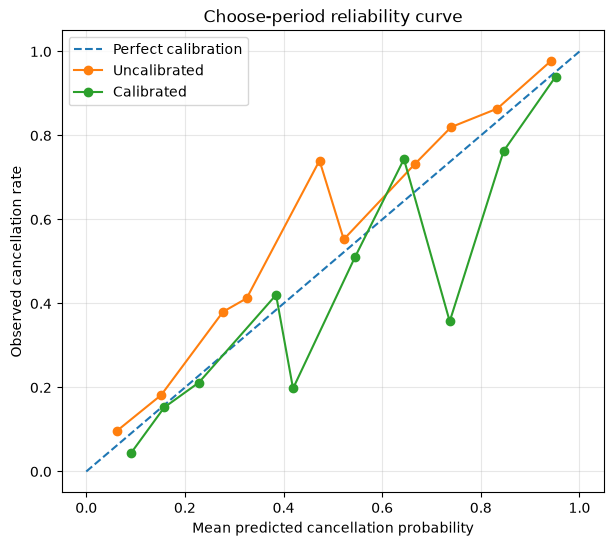

In [12]:
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    uncalibrated_reliability["mean_predicted_probability"],
    uncalibrated_reliability["observed_cancellation_rate"],
    marker="o",
    label="Uncalibrated"
)

plt.plot(
    calibrated_reliability["mean_predicted_probability"],
    calibrated_reliability["observed_cancellation_rate"],
    marker="o",
    label="Calibrated"
)

plt.xlabel("Mean predicted cancellation probability")
plt.ylabel("Observed cancellation rate")
plt.title("Choose-period reliability curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Check calibration separately by hotel

A model can look calibrated overall while being miscalibrated for one property. We calculate Brier score separately for each hotel and probability method.

In [13]:
hotel_calibration_rows = []

for hotel_name, hotel_rows in choose.groupby("hotel"):
    row_index = hotel_rows.index
    actual = y_choose.loc[row_index]

    for probability_name in ["uncalibrated", "calibrated"]:
        hotel_calibration_rows.append({
            "hotel": hotel_name,
            "probability_method": probability_name,
            "brier_score": brier_score_loss(
                actual,
                choose_probability_table.loc[row_index, probability_name]
            )
        })

hotel_calibration_metrics = pd.DataFrame(hotel_calibration_rows)
display(
    hotel_calibration_metrics.pivot(
        index="probability_method",
        columns="hotel",
        values="brier_score"
    )
)

hotel,City Hotel,Resort Hotel
probability_method,,
calibrated,0.205318,0.191922
uncalibrated,0.217204,0.191480


## 13. Save calibration evidence

The saved evidence includes out-of-fold Train probabilities, Choose probabilities, metric tables and reliability tables. The model itself is not yet a final production artifact.

In [14]:
evidence_folder = Path("evidence/probability_calibration")
evidence_folder.mkdir(parents=True, exist_ok=True)

pd.DataFrame({
    "actual": y_train.loc[calibration_rows],
    "oof_probability": oof_probability.loc[calibration_rows]
}).to_csv(
    evidence_folder / "train_out_of_fold_probabilities.csv",
    index=True
)

choose_probability_table.to_csv(
    evidence_folder / "choose_calibrated_probabilities.csv",
    index=True
)

calibration_metrics.to_csv(
    evidence_folder / "choose_calibration_metrics.csv",
    index=False
)

uncalibrated_reliability.to_csv(
    evidence_folder / "choose_uncalibrated_reliability.csv",
    index=False
)

calibrated_reliability.to_csv(
    evidence_folder / "choose_calibrated_reliability.csv",
    index=False
)

hotel_calibration_metrics.to_csv(
    evidence_folder / "choose_hotel_calibration_metrics.csv",
    index=False
)

print("Saved calibration evidence to:", evidence_folder)

Saved calibration evidence to: evidence\probability_calibration


## 14. Decide whether calibration is useful

Do not automatically keep the calibrated probabilities. Review:
- Did Brier score improve?
- Did log loss improve?
- Is the reliability curve closer to the diagonal?
- Did calibration help both hotels, or only one?
- Are the changes meaningful given the number of bookings in each bin?

Record the decision and rationale in `docs/DECISIONS.md`. If calibration makes performance worse or unstable, retain the uncalibrated model and explain why.

### Limitations

- The calibration mapping is trained on out-of-fold predictions from expanding Train folds.
- The final base model is fitted on all Train rows; its score distribution may differ from the fold models.
- Choose is used for evaluation after calibration is fitted, not to fit the calibrator.
- Calibration does not correct feature leakage, missing capacity data or model drift.
- The dataset was already explored, so this is retrospective rather than historically blind.

### Questions

1. What does it mean for a probability model to be calibrated?
2. Why should calibration use out-of-fold predictions rather than in-sample predictions?
3. Why is ROC AUC not a calibration metric?
4. Why can a calibrated model still make poor nightly decisions?
5. What does the reliability curve show that one Brier score cannot?

**Next notebook:** `10_uncertainty_and_conformal.ipynb`, where we examine uncertainty in nightly cancellation totals and the limits of prediction intervals.

In [15]:
# Decision rule, fixed before this notebook was run (recorded in docs/DECISIONS.md):
# adopt calibrated probabilities for the policy experiment only if they lower BOTH the
# Brier score AND the log loss on Choose. Otherwise keep the uncalibrated probabilities.
import json

metrics = calibration_metrics.set_index("probability_method")
brier_better = bool(metrics.loc["calibrated", "brier_score"] < metrics.loc["uncalibrated", "brier_score"])
log_loss_better = bool(metrics.loc["calibrated", "log_loss"] < metrics.loc["uncalibrated", "log_loss"])
use_calibrated = brier_better and log_loss_better

hotel_view = hotel_calibration_metrics.pivot(index="hotel", columns="probability_method", values="brier_score")
calibration_decision = {
    "base_model": BASE_MODEL_NAME,
    "base_settings": BASE_MODEL_SETTINGS,
    "rule": "use calibrated probabilities only if Choose Brier score AND Choose log loss both improve",
    "choose_brier_uncalibrated": float(metrics.loc["uncalibrated", "brier_score"]),
    "choose_brier_calibrated": float(metrics.loc["calibrated", "brier_score"]),
    "choose_log_loss_uncalibrated": float(metrics.loc["uncalibrated", "log_loss"]),
    "choose_log_loss_calibrated": float(metrics.loc["calibrated", "log_loss"]),
    "hotels_where_calibration_lowered_brier": [h for h, r in hotel_view.iterrows() if r["calibrated"] < r["uncalibrated"]],
    "use_calibrated_probabilities": use_calibrated,
    # The fitted sigmoid mapping, so later notebooks apply exactly this calibration:
    # calibrated = 1 / (1 + exp(-(intercept + coefficient * base_probability)))
    "calibrator_intercept": float(calibrator.intercept_[0]),
    "calibrator_coefficient": float(calibrator.coef_[0][0]),
}
(evidence_folder / "calibration_decision.json").write_text(json.dumps(calibration_decision, indent=2) + "\n", encoding="utf-8")
for key, value in calibration_decision.items():
    print(f"{key}: {value}")

base_model: logistic_regression
base_settings: {'C': 0.1}
rule: use calibrated probabilities only if Choose Brier score AND Choose log loss both improve
choose_brier_uncalibrated: 0.20906609937251733
choose_brier_calibrated: 0.2010803774182625
choose_log_loss_uncalibrated: 0.6104556816054038
choose_log_loss_calibrated: 0.5857425928330905
hotels_where_calibration_lowered_brier: ['City Hotel']
use_calibrated_probabilities: True
calibrator_intercept: -2.331608914325286
calibrator_coefficient: 5.954046917302593
